In [37]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [38]:
import catboost

In [39]:
df = pd.read_csv("Data/data_kern_ratios.csv")

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3099 entries, 0 to 3098
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Mg                 3099 non-null   float64
 1   Al                 3099 non-null   float64
 2   Si                 3099 non-null   float64
 3   P                  3099 non-null   float64
 4   S                  3099 non-null   float64
 5   K                  3099 non-null   float64
 6   Ca                 3099 non-null   float64
 7   Ti                 3099 non-null   float64
 8   Mn                 3099 non-null   float64
 9   Fe                 3099 non-null   float64
 10  Ni                 3099 non-null   float64
 11  Cu                 3099 non-null   float64
 12  Zn                 3099 non-null   float64
 13  Se                 3099 non-null   float64
 14  Rb                 3099 non-null   float64
 15  Sr                 3099 non-null   float64
 16  Zr                 3099 

In [41]:
df['Strat'].value_counts().sort_index()

Strat
0     430
1     155
2     193
3     270
4     236
5     145
6     150
7     191
8     392
9     491
10    298
11    148
Name: count, dtype: int64

**Отобранные признаки**

In [42]:
ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)',
    'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S',
    'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)'
]

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по соотношениям элементов**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9802
F1 macro (val):   0.3694
Gap (train-val):  0.6109

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9800    0.3889    0.5568       126
           1     0.3939    0.2549    0.3095        51
           2     0.3500    0.3043    0.3256        46
           3     0.4468    0.5833    0.5060        72
           4     0.6944    0.5556    0.6173        45
           5     0.0000    0.0000    0.0000         7
           6     0.3571    0.2326    0.2817        43
           7     0.3571    0.1351    0.1961        37
           8     0.1799    0.5000    0.2646        50
           9     0.4962    0.8354    0.6226        79
          10     0.8462    0.3056    0.4490        72
          11     0.3571    0.2632    0.3030        19

    accuracy                    

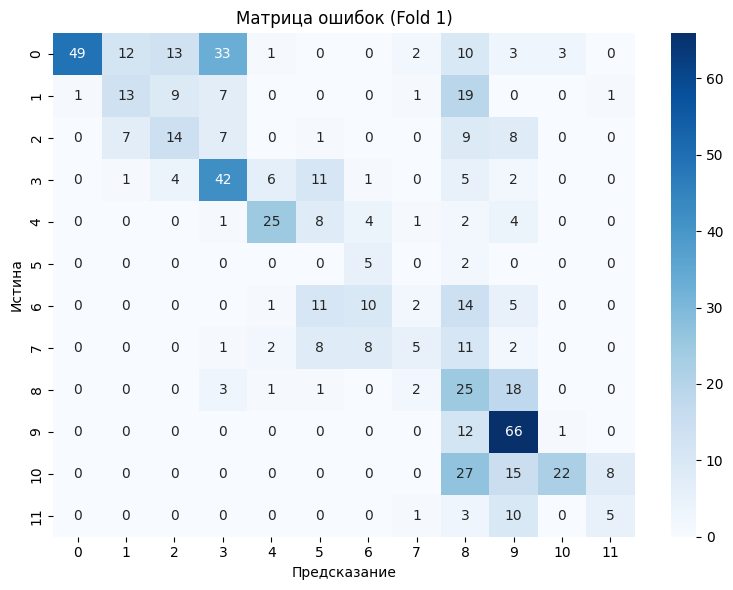

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9826
F1 macro (val):   0.6541
Gap (train-val):  0.3285

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8000    0.8718    0.8344        78
           1     0.6800    0.3864    0.4928        44
           2     0.4677    0.5800    0.5179        50
           3     0.7460    0.6528    0.6963        72
           4     0.6168    0.8571    0.7174        77
           5     0.4643    0.3514    0.4000        37
           6     0.5455    0.4286    0.4800        28
           7     0.5556    0.5357    0.5455        28
           8     0.6905    0.7250    0.7073        80
           9     0.8058    0.7830    0.7943       106
          10     0.8438    0.7500    0.7941        36
          11     0.9091    0.8333    0.8696        24

    accuracy                    

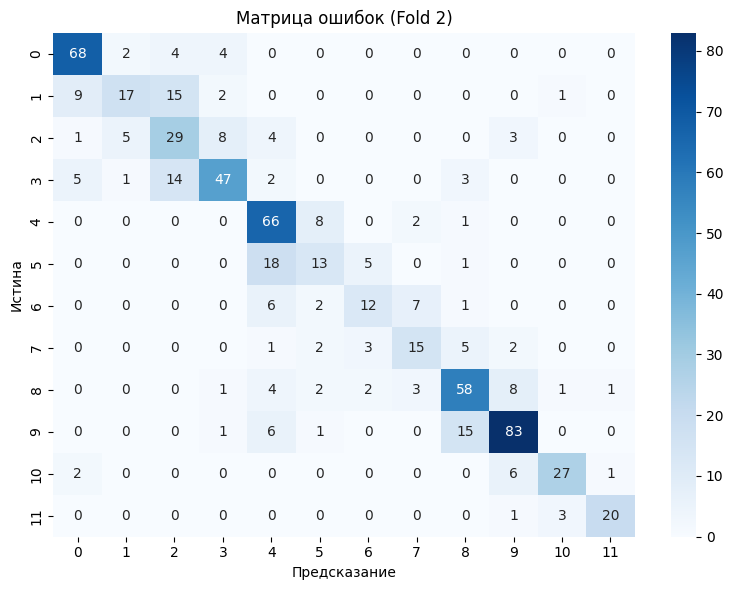

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9847
F1 macro (val):   0.5107
Gap (train-val):  0.4741

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9167    0.9565    0.9362        69
           1     0.3000    0.4286    0.3529        14
           2     0.4884    0.5250    0.5060        40
           3     0.6429    0.5400    0.5870        50
           4     0.7174    0.6111    0.6600        54
           5     0.6000    0.3333    0.4286        36
           6     0.3200    0.4444    0.3721        18
           7     0.2400    0.1579    0.1905        38
           8     0.5238    0.4400    0.4783        75
           9     0.5462    0.8161    0.6544        87
          10     0.5000    0.7705    0.6065        61
          11     0.6154    0.2500    0.3556        64

    accuracy                    

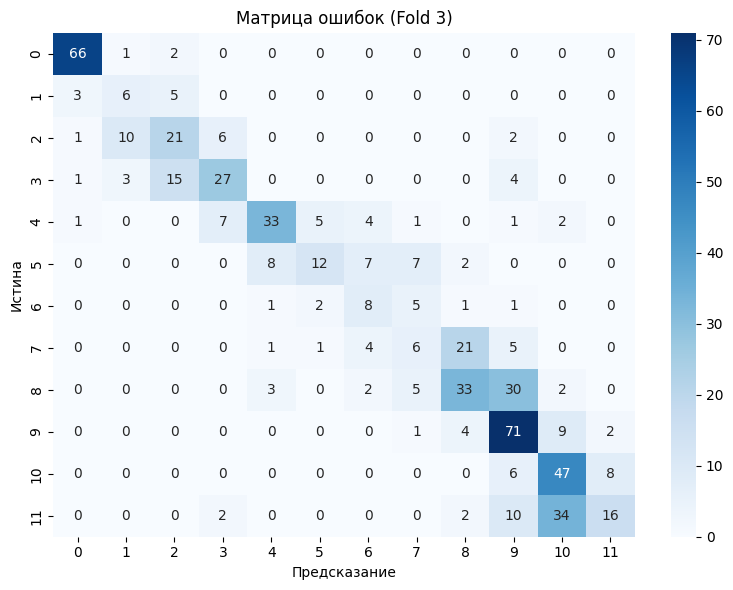

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9823
F1 macro (val):   0.5607
Gap (train-val):  0.4216

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9756    0.8333    0.8989        96
           1     0.7778    0.3684    0.5000        19
           2     0.6250    0.8929    0.7353        28
           3     0.7500    0.8438    0.7941        32
           4     0.6579    0.8065    0.7246        31
           5     0.1562    0.1111    0.1299        45
           6     0.4074    0.2683    0.3235        41
           7     0.2432    0.1500    0.1856        60
           8     0.4923    0.5565    0.5224       115
           9     0.5918    0.6824    0.6339        85
          10     0.5821    0.9070    0.7091        43
          11     0.6667    0.5000    0.5714         4

    accuracy                    

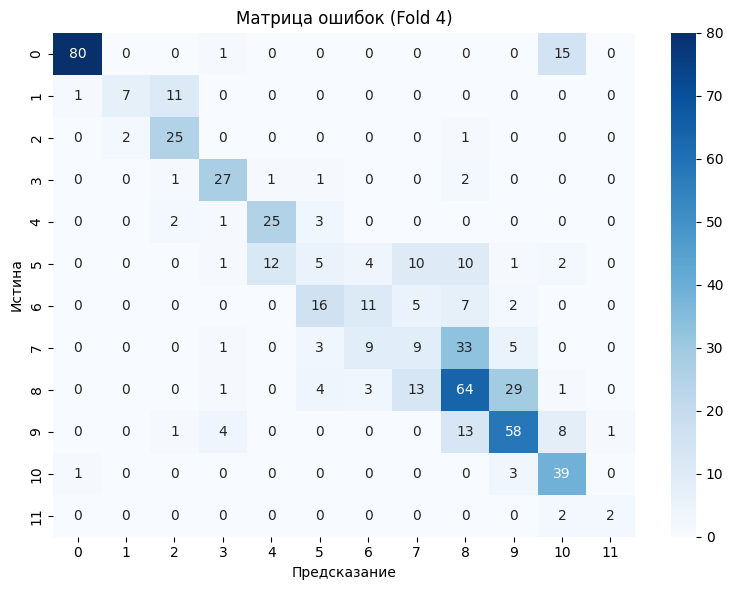

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9774
F1 macro (val):   0.5232
Gap (train-val):  0.4542

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.7027    0.8525    0.7704        61
           1     0.5294    0.3333    0.4091        27
           2     0.4474    0.5862    0.5075        29
           3     0.7826    0.8182    0.8000        44
           4     0.5789    0.7586    0.6567        29
           5     0.1905    0.2000    0.1951        20
           6     0.3571    0.2500    0.2941        20
           7     0.2857    0.2143    0.2449        28
           8     0.4231    0.6111    0.5000        72
           9     0.6641    0.6343    0.6489       134
          10     0.7778    0.4070    0.5344        86
          11     0.6829    0.7568    0.7179        37

    accuracy                    

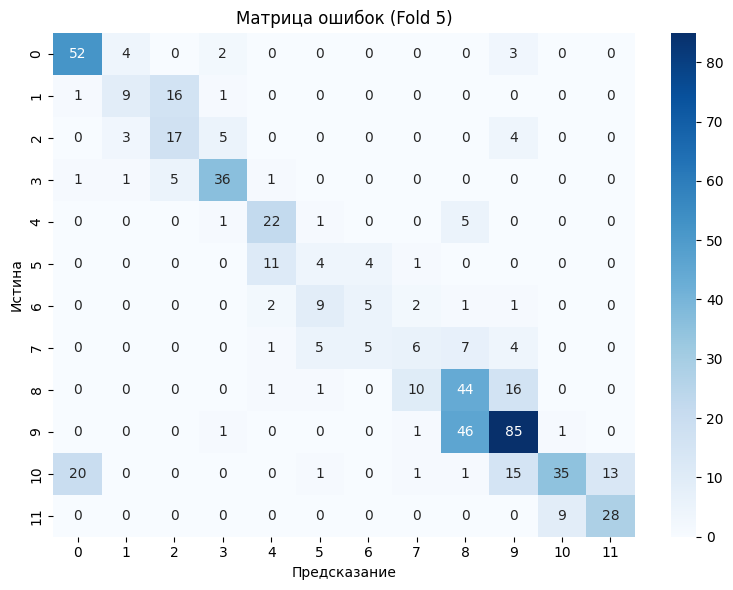

Результаты кросс-валидации
  Fold 1: F1_macro = 0.3694
  Fold 2: F1_macro = 0.6541
  Fold 3: F1_macro = 0.5107
  Fold 4: F1_macro = 0.5607
  Fold 5: F1_macro = 0.5232

  Средний F1 macro: 0.5236 ± 0.0921

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8678    0.7326    0.7945       430
           1     0.5000    0.3355    0.4015       155
           2     0.4753    0.5492    0.5096       193
           3     0.6370    0.6630    0.6497       270
           4     0.6453    0.7246    0.6826       236
           5     0.2411    0.2345    0.2378       145
           6     0.3966    0.3067    0.3459       150
           7     0.3306    0.2147    0.2603       191
           8     0.4308    0.5714    0.4912       392
           9     0.6132    0.7393    0.6704       491
          10     0.6439    0.5705    0.6050       298
          11     0.6698    0.4797    0.5591       148

    accuracy                         0.5718      

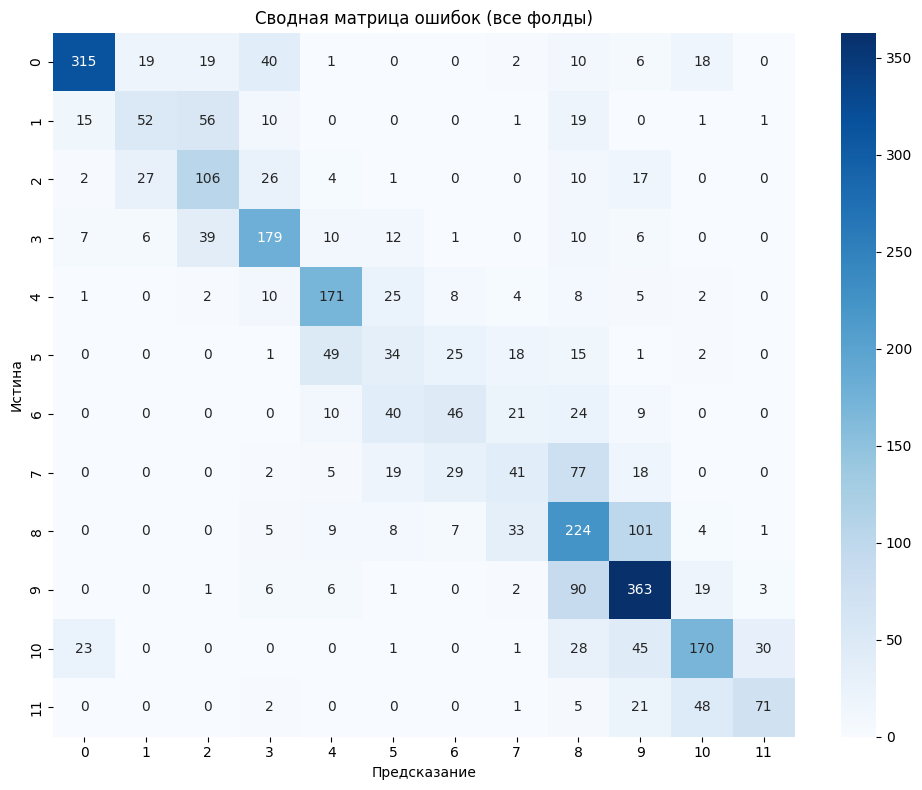

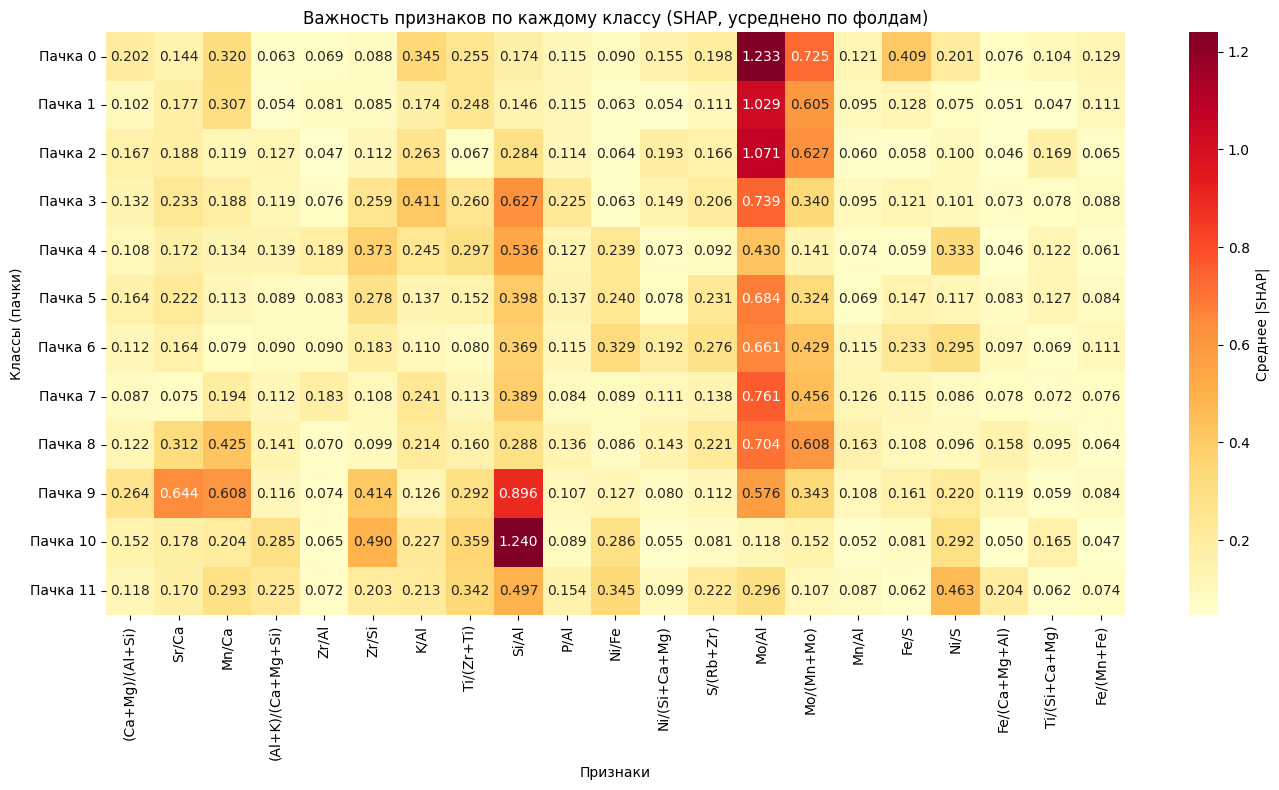

Пачка 0:
  Mo/Al: 1.233
  Mo/(Mn+Mo): 0.725
  Fe/S: 0.409
  K/Al: 0.345
  Mn/Ca: 0.320
  Ti/(Zr+Ti): 0.255
  (Ca+Mg)/(Al+Si): 0.202
  Ni/S: 0.201
  S/(Rb+Zr): 0.198
  Si/Al: 0.174
  Ni/(Si+Ca+Mg): 0.155
  Sr/Ca: 0.144
  Fe/(Mn+Fe): 0.129
  Mn/Al: 0.121
  P/Al: 0.115
  Ti/(Si+Ca+Mg): 0.104

Пачка 1:
  Mo/Al: 1.029
  Mo/(Mn+Mo): 0.605
  Mn/Ca: 0.307
  Ti/(Zr+Ti): 0.248
  Sr/Ca: 0.177
  K/Al: 0.174
  Si/Al: 0.146
  Fe/S: 0.128
  P/Al: 0.115
  S/(Rb+Zr): 0.111
  Fe/(Mn+Fe): 0.111
  (Ca+Mg)/(Al+Si): 0.102

Пачка 2:
  Mo/Al: 1.071
  Mo/(Mn+Mo): 0.627
  Si/Al: 0.284
  K/Al: 0.263
  Ni/(Si+Ca+Mg): 0.193
  Sr/Ca: 0.188
  Ti/(Si+Ca+Mg): 0.169
  (Ca+Mg)/(Al+Si): 0.167
  S/(Rb+Zr): 0.166
  (Al+K)/(Ca+Mg+Si): 0.127
  Mn/Ca: 0.119
  P/Al: 0.114
  Zr/Si: 0.112

Пачка 3:
  Mo/Al: 0.739
  Si/Al: 0.627
  K/Al: 0.411
  Mo/(Mn+Mo): 0.340
  Ti/(Zr+Ti): 0.260
  Zr/Si: 0.259
  Sr/Ca: 0.233
  P/Al: 0.225
  S/(Rb+Zr): 0.206
  Mn/Ca: 0.188
  Ni/(Si+Ca+Mg): 0.149
  (Ca+Mg)/(Al+Si): 0.132
  Fe/S: 0.121
  (Al+K)/(

/tmp/ipykernel_375205/2791398286.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

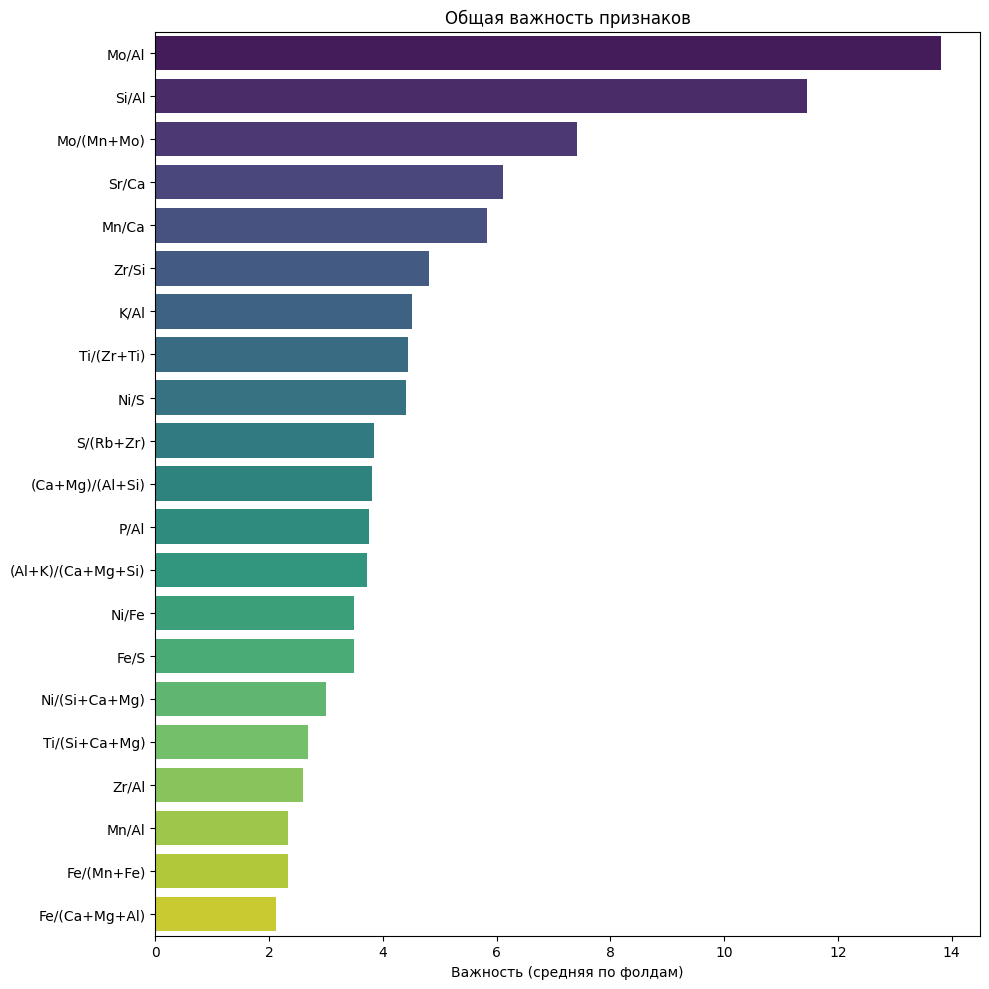

In [43]:
X = df[ratios]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
results_df = pd.concat(results_df_list, ignore_index=True)
results_df.to_csv('Result/classification_results_CatBoost_fixed_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# SHAP: важность по классам (усреднённая по всем фолдам)
# Объединяем SHAP всех фолдов
shap_concat = np.concatenate(shap_all, axis=0)  # (total_samples, n_classes, n_features)
mean_shap = np.abs(shap_concat).mean(axis=0)     # (n_classes, n_features)

plt.figure(figsize=(14, 8))
sns.heatmap(
    mean_shap,
    annot=True, fmt='.3f',
    cmap='YlOrRd',
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Среднее |SHAP|'}
)
plt.xlabel('Признаки')
plt.ylabel('Классы (пачки)')
plt.title('Важность признаков по каждому классу (SHAP, усреднено по фолдам)')
plt.tight_layout()
plt.show()

# Топ-признаки для каждого класса
for i in range(mean_shap.shape[0]):
    significant = [(ratios[j], mean_shap[i, j])
                   for j in range(len(ratios))
                   if mean_shap[i, j] > 0.1]
    significant.sort(key=lambda x: -x[1])
    print(f"Пачка {i}:")
    for feat, v in significant:
        print(f"  {feat}: {v:.3f}")
    print()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(ratios, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам и соотношениям элементов**

**39 признаков**

In [44]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)',
    'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S',
    'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9874
F1 macro (val):   0.4378
Gap (train-val):  0.5496

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9538    0.4921    0.6492       126
           1     0.3889    0.2745    0.3218        51
           2     0.2843    0.6304    0.3919        46
           3     0.6623    0.7083    0.6846        72
           4     0.6383    0.6667    0.6522        45
           5     0.0000    0.0000    0.0000         7
           6     0.4194    0.3023    0.3514        43
           7     0.3200    0.2162    0.2581        37
           8     0.3462    0.5400    0.4219        50
           9     0.5167    0.7848    0.6231        79
          10     0.8824    0.4167    0.5660        72
          11     0.3529    0.3158    0.3333        19

    accuracy                    

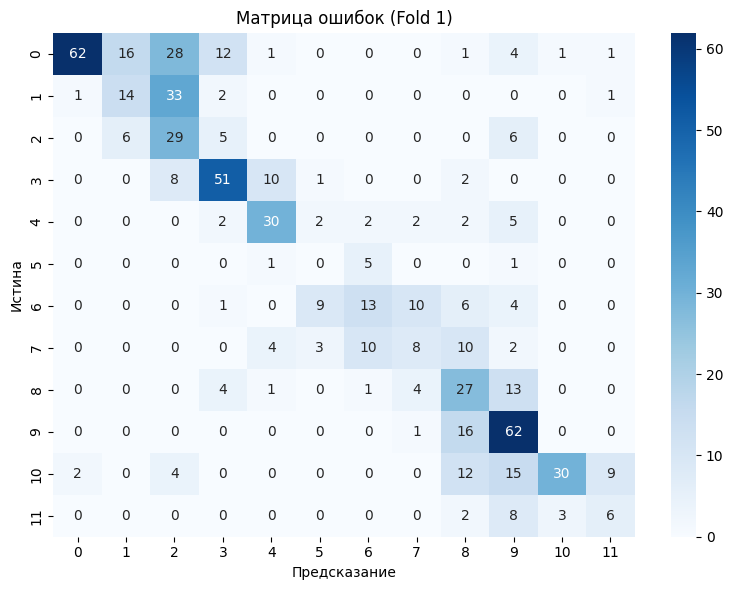

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9902
F1 macro (val):   0.6875
Gap (train-val):  0.3026

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8222    0.9487    0.8810        78
           1     0.7407    0.4545    0.5634        44
           2     0.6600    0.6600    0.6600        50
           3     0.8406    0.8056    0.8227        72
           4     0.6300    0.8182    0.7119        77
           5     0.5185    0.3784    0.4375        37
           6     0.5714    0.2857    0.3810        28
           7     0.4706    0.5714    0.5161        28
           8     0.6588    0.7000    0.6788        80
           9     0.8091    0.8396    0.8241       106
          10     0.8788    0.8056    0.8406        36
          11     1.0000    0.8750    0.9333        24

    accuracy                    

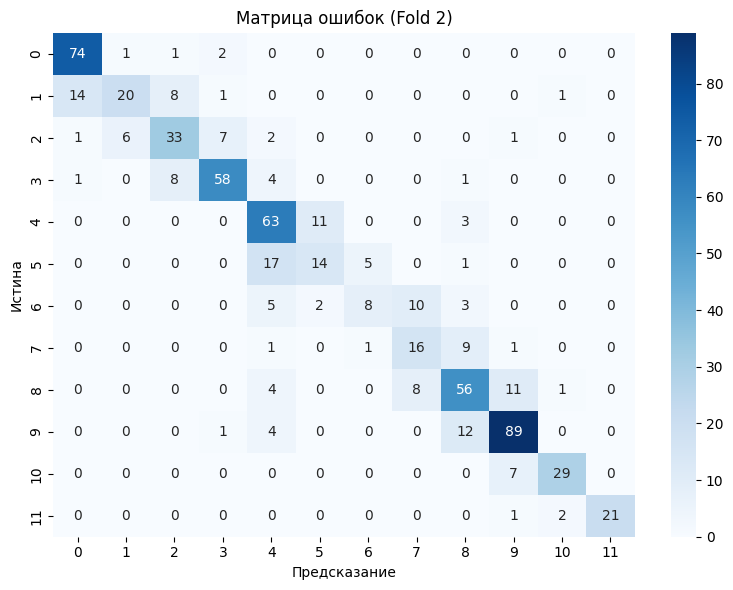

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9915
F1 macro (val):   0.5558
Gap (train-val):  0.4357

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9306    0.9710    0.9504        69
           1     0.4000    0.2857    0.3333        14
           2     0.4906    0.6500    0.5591        40
           3     0.6957    0.6400    0.6667        50
           4     0.7632    0.5370    0.6304        54
           5     0.5652    0.3611    0.4407        36
           6     0.3448    0.5556    0.4255        18
           7     0.4286    0.2368    0.3051        38
           8     0.5541    0.5467    0.5503        75
           9     0.6195    0.8046    0.7000        87
          10     0.5172    0.7377    0.6081        61
          11     0.6500    0.4062    0.5000        64

    accuracy                    

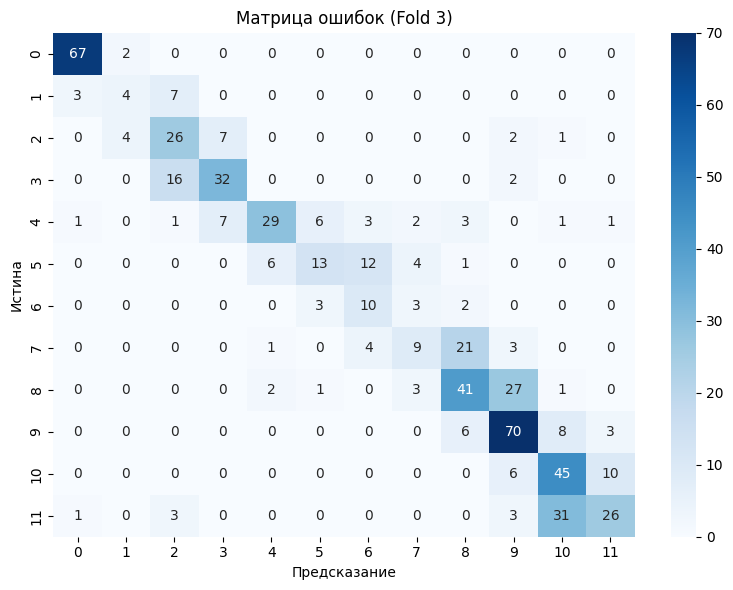

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9863
F1 macro (val):   0.6231
Gap (train-val):  0.3632

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9783    0.9375    0.9574        96
           1     0.6667    0.4211    0.5161        19
           2     0.6842    0.9286    0.7879        28
           3     0.8235    0.8750    0.8485        32
           4     0.5435    0.8065    0.6494        31
           5     0.2973    0.2444    0.2683        45
           6     0.3182    0.1707    0.2222        41
           7     0.2778    0.1667    0.2083        60
           8     0.5847    0.6000    0.5923       115
           9     0.6389    0.8118    0.7150        85
          10     0.7736    0.9535    0.8542        43
          11     1.0000    0.7500    0.8571         4

    accuracy                    

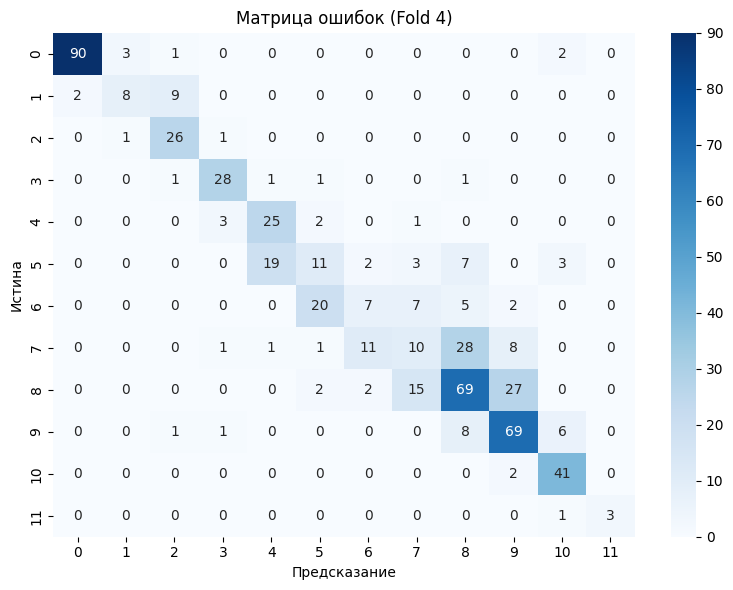

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9847
F1 macro (val):   0.5694
Gap (train-val):  0.4153

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8485    0.9180    0.8819        61
           1     0.5000    0.3704    0.4255        27
           2     0.4324    0.5517    0.4848        29
           3     0.8636    0.8636    0.8636        44
           4     0.6857    0.8276    0.7500        29
           5     0.3182    0.3500    0.3333        20
           6     0.2222    0.2000    0.2105        20
           7     0.3043    0.2500    0.2745        28
           8     0.4494    0.5556    0.4969        72
           9     0.6667    0.6866    0.6765       134
          10     0.8868    0.5465    0.6763        86
          11     0.7143    0.8108    0.7595        37

    accuracy                    

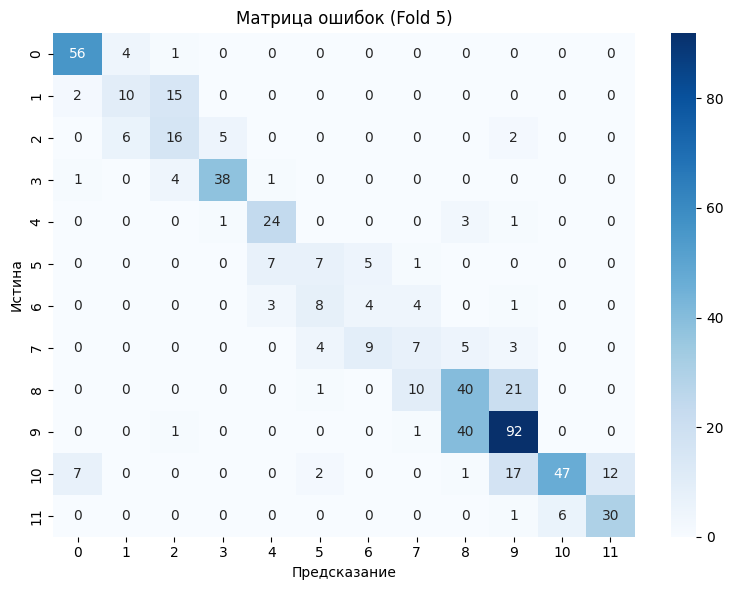

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4378
  Fold 2: F1_macro = 0.6875
  Fold 3: F1_macro = 0.5558
  Fold 4: F1_macro = 0.6231
  Fold 5: F1_macro = 0.5694

  Средний F1 macro: 0.5747 ± 0.0827

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9065    0.8116    0.8564       430
           1     0.5333    0.3613    0.4308       155
           2     0.4643    0.6736    0.5497       193
           3     0.7667    0.7667    0.7667       270
           4     0.6429    0.7246    0.6813       236
           5     0.3629    0.3103    0.3346       145
           6     0.3684    0.2800    0.3182       150
           7     0.3597    0.2618    0.3030       191
           8     0.5248    0.5944    0.5574       392
           9     0.6486    0.7780    0.7074       491
          10     0.7385    0.6443    0.6882       298
          11     0.6992    0.5811    0.6347       148

    accuracy                         0.6270      

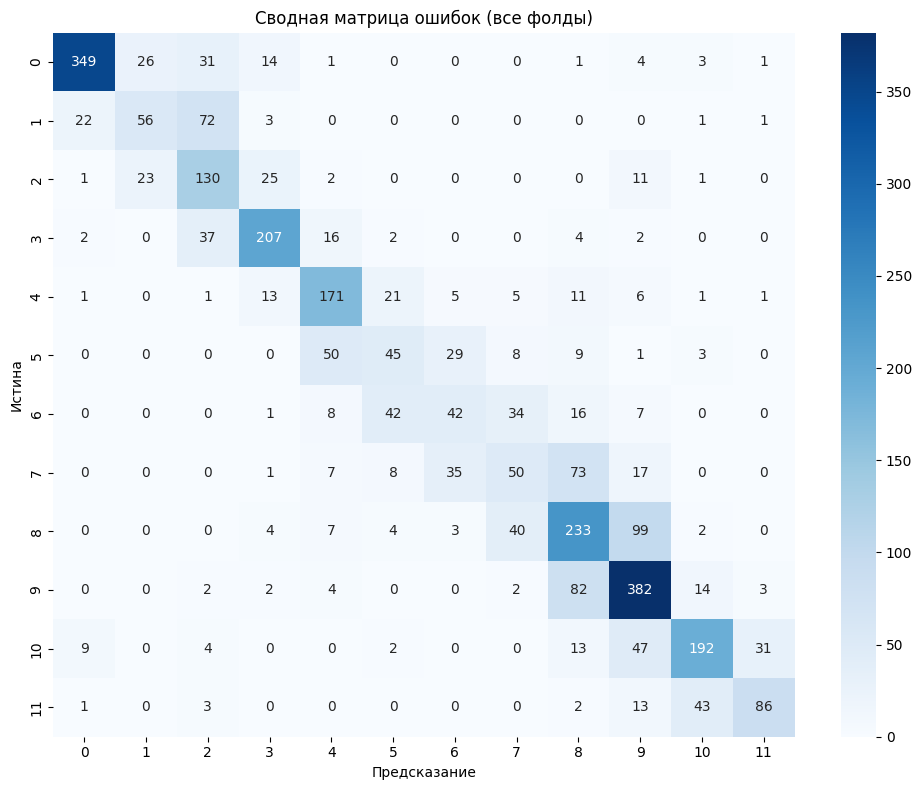

/tmp/ipykernel_375205/2156245639.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

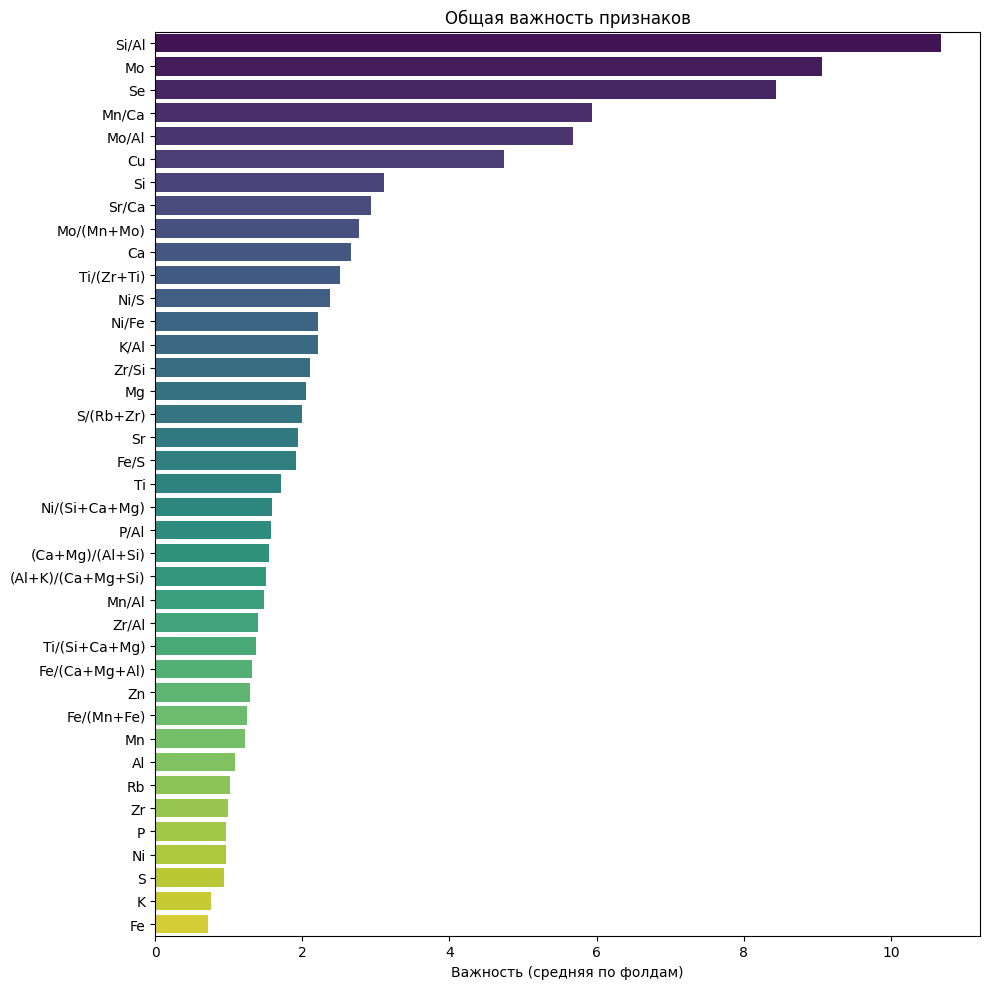

In [45]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
results_df = pd.concat(results_df_list, ignore_index=True)
results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

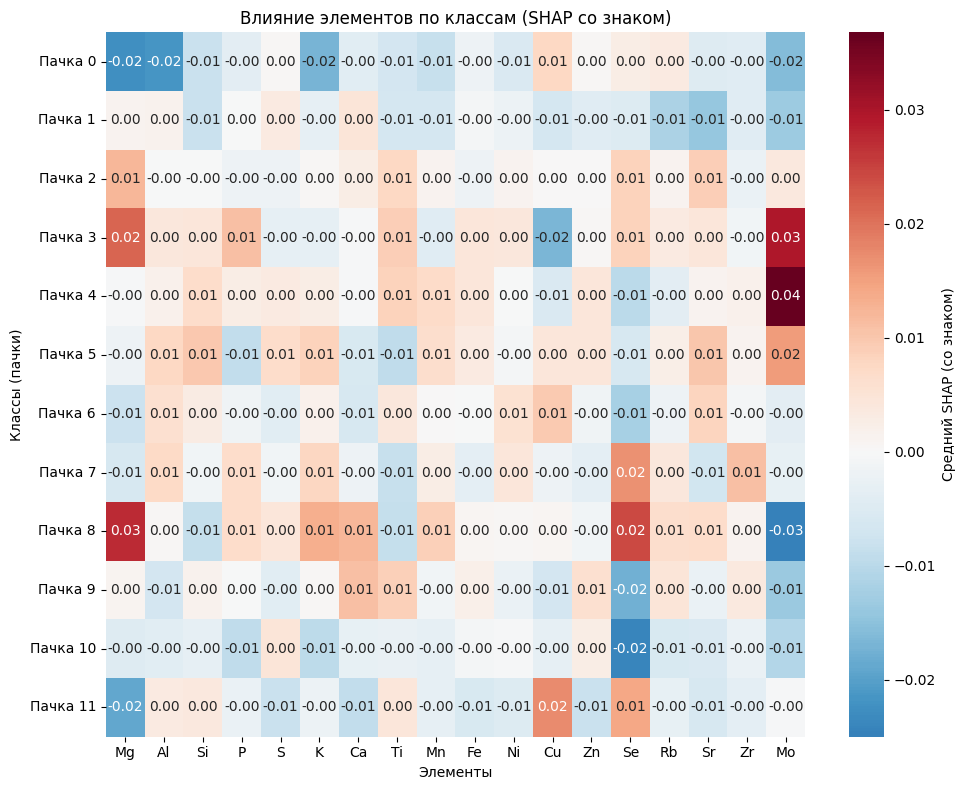

Пачка 0:
  ↓ Mg: -0.023
  ↓ Al: -0.022
  ↓ K: -0.017
  ↓ Mo: -0.016

Пачка 1:
  ↓ Sr: -0.014
  ↓ Mo: -0.013
  ↓ Rb: -0.012

Пачка 2:
  ↑ Mg: +0.012

Пачка 3:
  ↑ Mo: +0.030
  ↑ Mg: +0.021
  ↓ Cu: -0.017
  ↑ P: +0.011

Пачка 4:
  ↑ Mo: +0.037

Пачка 5:
  ↑ Mo: +0.016
  ↑ Sr: +0.010

Пачка 6:
  ↓ Se: -0.012

Пачка 7:
  ↑ Se: +0.017
  ↑ Zr: +0.011

Пачка 8:
  ↑ Mg: +0.027
  ↓ Mo: -0.025
  ↑ Se: +0.024
  ↑ K: +0.013
  ↑ Ca: +0.012

Пачка 9:
  ↓ Se: -0.018
  ↓ Mo: -0.014
  ↑ Ca: +0.011

Пачка 10:
  ↓ Se: -0.024
  ↓ Mo: -0.011

Пачка 11:
  ↓ Mg: -0.019
  ↑ Cu: +0.017
  ↑ Se: +0.014



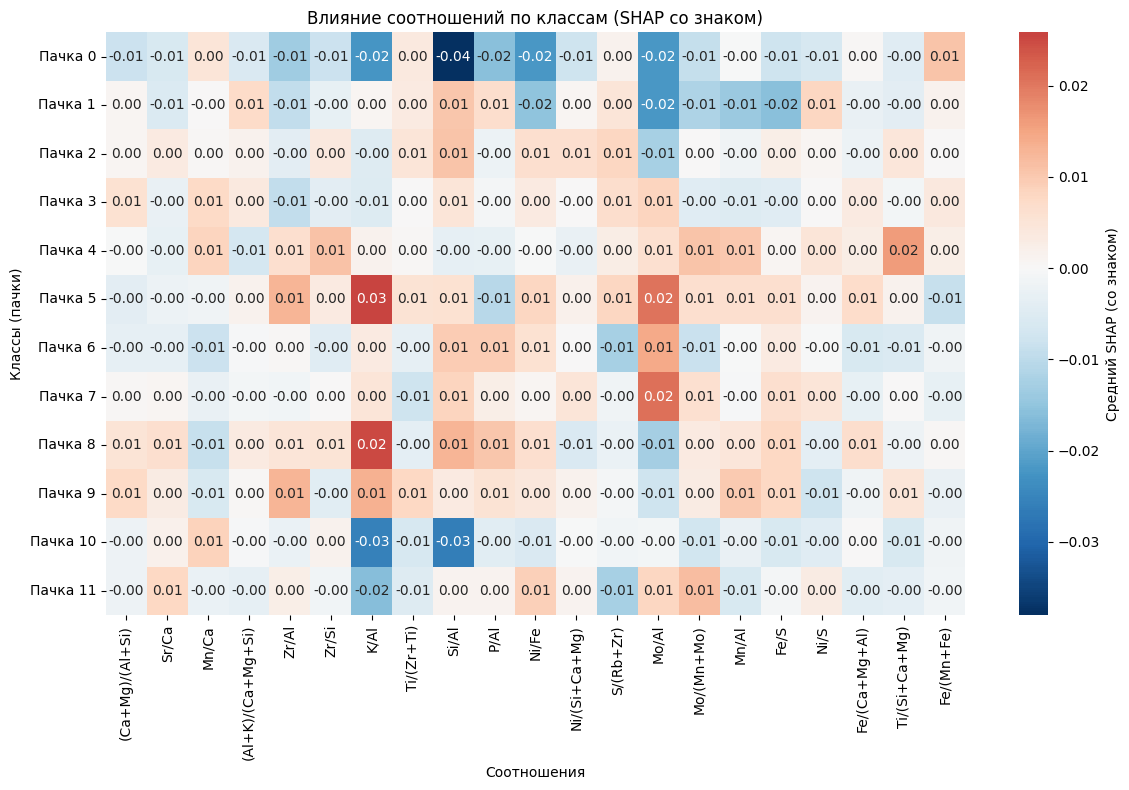

Пачка 0:
  ↓ Si/Al: -0.038
  ↓ K/Al: -0.022
  ↓ Ni/Fe: -0.022
  ↓ Mo/Al: -0.022
  ↓ P/Al: -0.016
  ↓ Zr/Al: -0.014
  ↑ Fe/(Mn+Fe): +0.011

Пачка 1:
  ↓ Mo/Al: -0.022
  ↓ Fe/S: -0.016
  ↓ Ni/Fe: -0.015
  ↓ Mn/Al: -0.014
  ↓ Mo/(Mn+Mo): -0.012
  ↑ Si/Al: +0.011

Пачка 2:
  ↓ Mo/Al: -0.013
  ↑ Si/Al: +0.011

Пачка 3:

Пачка 4:
  ↑ Ti/(Si+Ca+Mg): +0.016
  ↑ Zr/Si: +0.011
  ↑ Mo/(Mn+Mo): +0.011
  ↑ Mn/Al: +0.010

Пачка 5:
  ↑ K/Al: +0.026
  ↑ Mo/Al: +0.020
  ↑ Zr/Al: +0.013
  ↓ P/Al: -0.010

Пачка 6:
  ↑ Mo/Al: +0.014
  ↓ S/(Rb+Zr): -0.013

Пачка 7:
  ↑ Mo/Al: +0.021

Пачка 8:
  ↑ K/Al: +0.025
  ↓ Mo/Al: -0.013
  ↑ Si/Al: +0.013
  ↑ P/Al: +0.010

Пачка 9:
  ↑ K/Al: +0.013
  ↑ Zr/Al: +0.013
  ↑ Mn/Al: +0.010

Пачка 10:
  ↓ Si/Al: -0.026
  ↓ K/Al: -0.026

Пачка 11:
  ↓ K/Al: -0.016
  ↓ S/(Rb+Zr): -0.013
  ↑ Mo/(Mn+Mo): +0.012



In [46]:
# SHAP со знаком, разделённый на элементы и соотношения
shap_concat = np.concatenate(shap_all, axis=0)  
mean_shap = shap_concat.mean(axis=0)             

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca',
          '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)',
          'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)',
          'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
          'Fe/S', 'Ni/S',
          'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)']

elem_idx = [features.index(e) for e in elements]
ratio_idx = [features.index(r) for r in ratios]

mean_shap_elem = mean_shap[:, elem_idx]    # (n_classes, n_elements)
mean_shap_ratio = mean_shap[:, ratio_idx]  # (n_classes, n_ratios)

# Таблица 1: Элементы
plt.figure(figsize=(10, 8))
sns.heatmap(
    mean_shap_elem,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=elements,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Элементы')
plt.ylabel('Классы (пачки)')
plt.title('Влияние элементов по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-элементов по пачкам
for i in range(mean_shap_elem.shape[0]):
    significant = [(elements[j], mean_shap_elem[i, j])
                   for j in range(len(elements))
                   if abs(mean_shap_elem[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()

# Таблица 2: Соотношения
plt.figure(figsize=(12, 8))
sns.heatmap(
    mean_shap_ratio,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Соотношения')
plt.ylabel('Классы (пачки)')
plt.title('Влияние соотношений по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-соотношений по пачкам
for i in range(mean_shap_ratio.shape[0]):
    significant = [(ratios[j], mean_shap_ratio[i, j])
                   for j in range(len(ratios))
                   if abs(mean_shap_ratio[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()


In [47]:
threshold = 0.01

# Элементы, где |SHAP| < 0.01 во всех пачках
weak_elems = [e for e, col in zip(elements, mean_shap_elem.T) if np.all(np.abs(col) < threshold)]

# Соотношения, где |SHAP| < 0.01 во всех пачках
weak_ratios = [r for r, col in zip(ratios, mean_shap_ratio.T) if np.all(np.abs(col) < threshold)]

print("Элементы:", weak_elems)
print("Соотношения:", weak_ratios)


Элементы: ['Si', 'S', 'Ti', 'Mn', 'Fe', 'Ni', 'Zn']
Соотношения: ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Ti/(Zr+Ti)', 'Ni/(Si+Ca+Mg)', 'Ni/S', 'Fe/(Ca+Mg+Al)']


**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам и соотношениям элементов. Только по наиболее важным признакам**

In [48]:
features = [
    'Mg', 'Al', 'P', 'K', 'Ca',
    'Cu', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    'Zr/Al', 'Zr/Si', 'K/Al',
    'Si/Al', 'P/Al', 'Ni/Fe', 
    'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9871
F1 macro (val):   0.4384
Gap (train-val):  0.5487

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9444    0.5397    0.6869       126
           1     0.4118    0.2745    0.3294        51
           2     0.2600    0.5652    0.3562        46
           3     0.7143    0.6944    0.7042        72
           4     0.5435    0.5556    0.5495        45
           5     0.0000    0.0000    0.0000         7
           6     0.4091    0.4186    0.4138        43
           7     0.3182    0.1892    0.2373        37
           8     0.2824    0.4800    0.3556        50
           9     0.5728    0.7468    0.6484        79
          10     0.8333    0.4167    0.5556        72
          11     0.5000    0.3684    0.4242        19

    accuracy                    

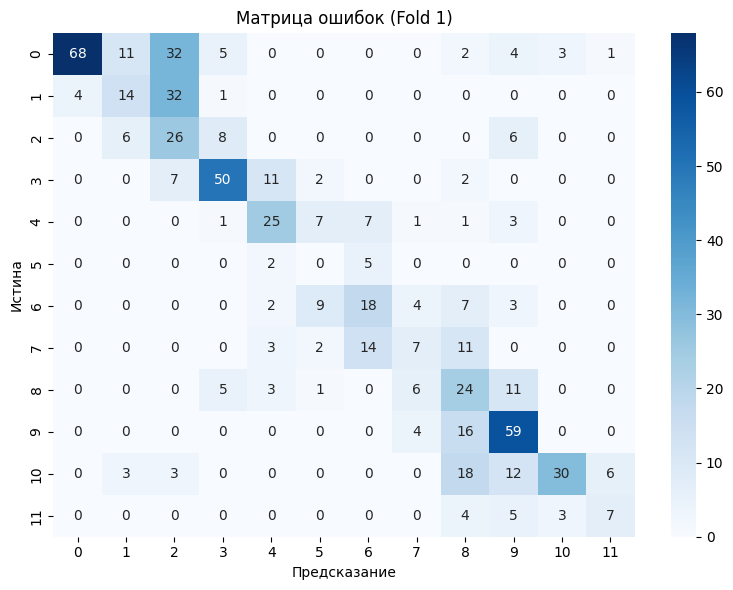

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9884
F1 macro (val):   0.6630
Gap (train-val):  0.3255

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8111    0.9359    0.8690        78
           1     0.7037    0.4318    0.5352        44
           2     0.6038    0.6400    0.6214        50
           3     0.8088    0.7639    0.7857        72
           4     0.6364    0.8182    0.7159        77
           5     0.5357    0.4054    0.4615        37
           6     0.5000    0.2143    0.3000        28
           7     0.3529    0.4286    0.3871        28
           8     0.6042    0.7250    0.6591        80
           9     0.8144    0.7453    0.7783       106
          10     0.9118    0.8611    0.8857        36
          11     1.0000    0.9167    0.9565        24

    accuracy                    

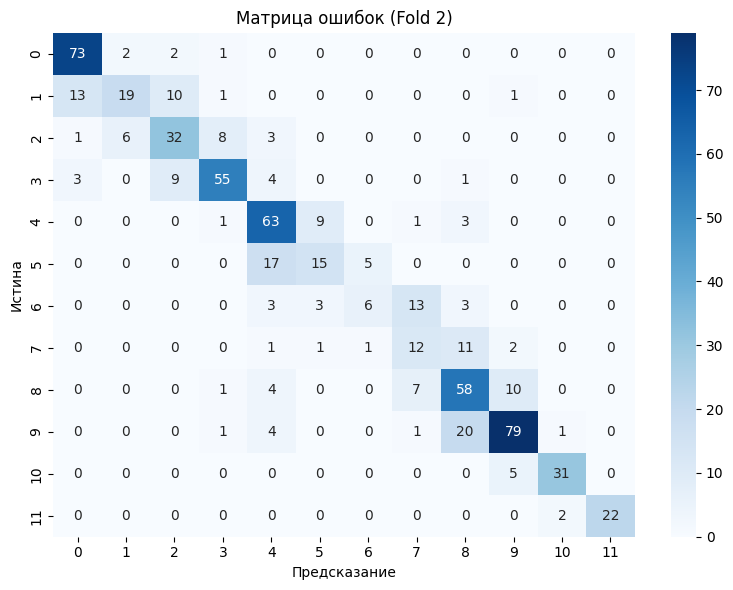

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9915
F1 macro (val):   0.5362
Gap (train-val):  0.4553

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9565    0.9565    0.9565        69
           1     0.2727    0.2143    0.2400        14
           2     0.4545    0.6250    0.5263        40
           3     0.6327    0.6200    0.6263        50
           4     0.7838    0.5370    0.6374        54
           5     0.6522    0.4167    0.5085        36
           6     0.3226    0.5556    0.4082        18
           7     0.3889    0.1842    0.2500        38
           8     0.5694    0.5467    0.5578        75
           9     0.6034    0.8046    0.6897        87
          10     0.5000    0.7541    0.6013        61
          11     0.6364    0.3281    0.4330        64

    accuracy                    

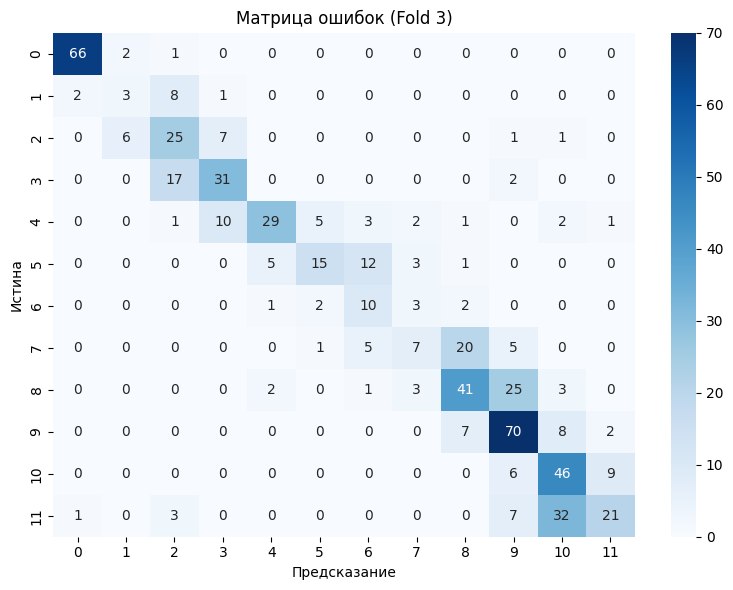

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9851
F1 macro (val):   0.6263
Gap (train-val):  0.3588

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9789    0.9688    0.9738        96
           1     0.8462    0.5789    0.6875        19
           2     0.7059    0.8571    0.7742        28
           3     0.8485    0.8750    0.8615        32
           4     0.5217    0.7742    0.6234        31
           5     0.2632    0.2222    0.2410        45
           6     0.3529    0.1463    0.2069        41
           7     0.2353    0.1333    0.1702        60
           8     0.5447    0.5826    0.5630       115
           9     0.6126    0.8000    0.6939        85
          10     0.7885    0.9535    0.8632        43
          11     1.0000    0.7500    0.8571         4

    accuracy                    

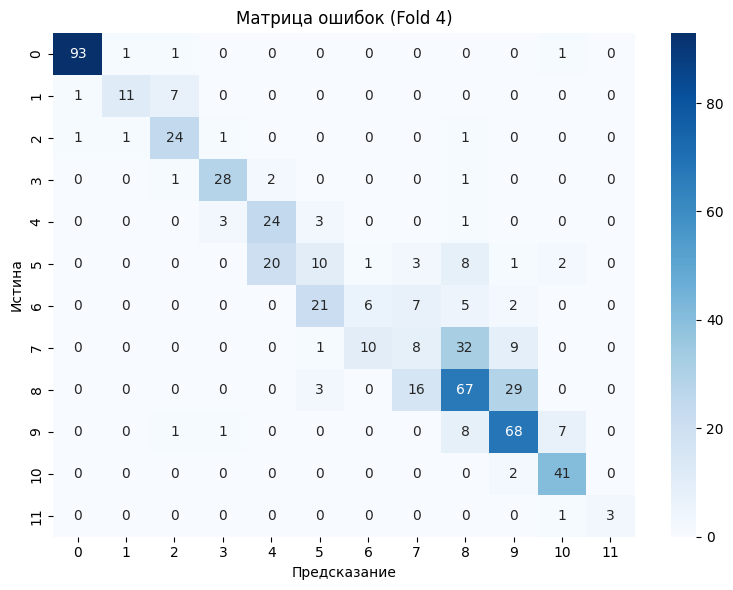

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9835
F1 macro (val):   0.5657
Gap (train-val):  0.4178

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8261    0.9344    0.8769        61
           1     0.6316    0.4444    0.5217        27
           2     0.4474    0.5862    0.5075        29
           3     0.8605    0.8409    0.8506        44
           4     0.6286    0.7586    0.6875        29
           5     0.3182    0.3500    0.3333        20
           6     0.2000    0.1500    0.1714        20
           7     0.3200    0.2857    0.3019        28
           8     0.4409    0.5694    0.4970        72
           9     0.6538    0.6343    0.6439       134
          10     0.8393    0.5465    0.6620        86
          11     0.6905    0.7838    0.7342        37

    accuracy                    

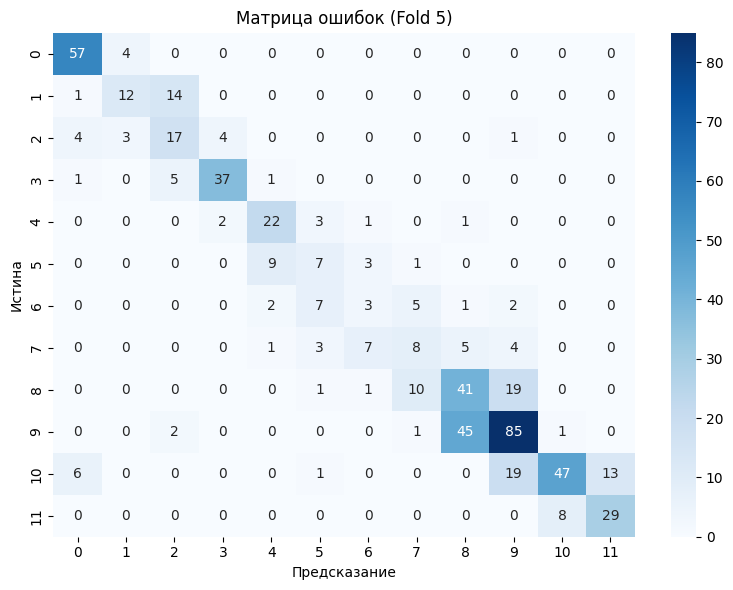

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4384
  Fold 2: F1_macro = 0.6630
  Fold 3: F1_macro = 0.5362
  Fold 4: F1_macro = 0.6263
  Fold 5: F1_macro = 0.5657

  Средний F1 macro: 0.5659 ± 0.0777

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9038    0.8302    0.8655       430
           1     0.5673    0.3806    0.4556       155
           2     0.4429    0.6425    0.5243       193
           3     0.7643    0.7444    0.7542       270
           4     0.6198    0.6907    0.6533       236
           5     0.3561    0.3241    0.3394       145
           6     0.3613    0.2867    0.3197       150
           7     0.3158    0.2199    0.2593       191
           8     0.4925    0.5893    0.5366       392
           9     0.6481    0.7352    0.6889       491
          10     0.7222    0.6544    0.6866       298
          11     0.7193    0.5541    0.6260       148

    accuracy                         0.6147      

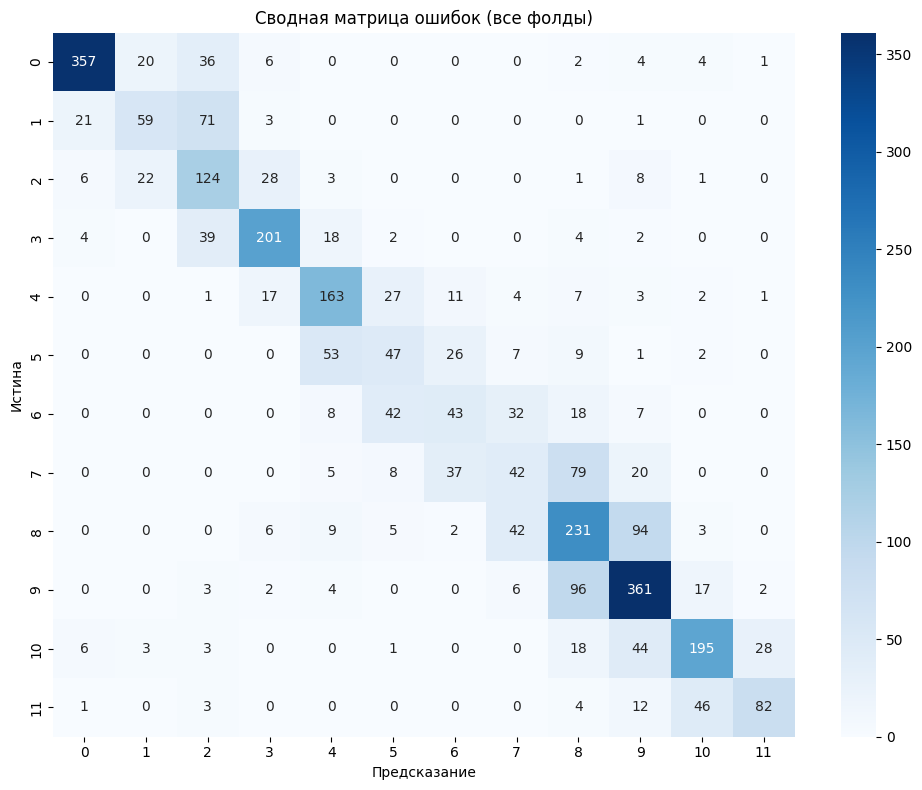

/tmp/ipykernel_375205/2631189579.py:127: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

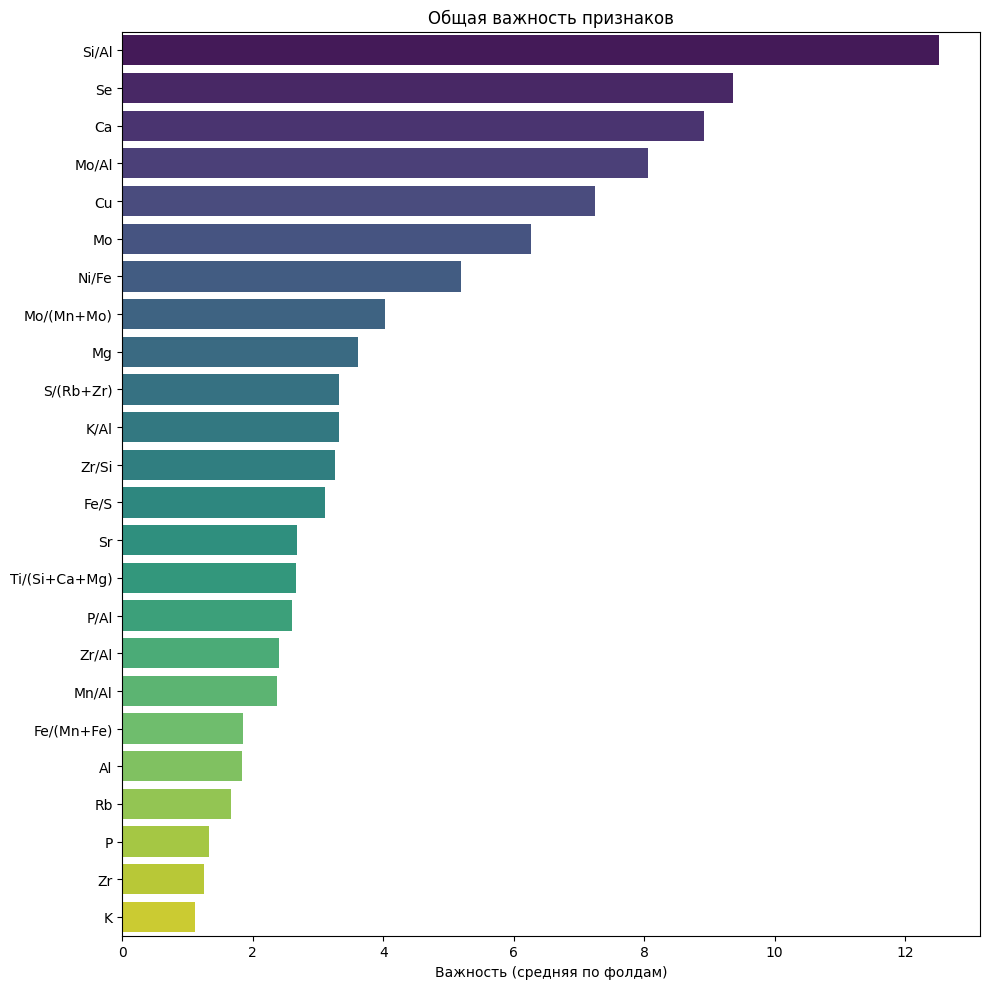

In [49]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Вывод: Удаление слабых признаков не помогло — F1 macro упал на 0.009, переобучение не снизилось.**

**Проблема не в признаках. Три разных набора (18, 39, 30) дают практически одинаковый результат: 0.57 ± 0.02. Переобучение (train 0.98, val 0.57) и провал на Fold 1 (A1, E1) сохраняются во всех случаях.
Корень проблемы — межскважинная вариативность. Модель заучивает паттерны конкретных скважин, а не геохимические сигналы пачек.**